# Agent Reinforcement Learning untuk Permainan Gaple (Domino)

**Link video presentasi (YouTube, Unlisted):** _tempel link di sini_

**Nama:** ...
**NRP:** 5054251009

---

Gaple adalah permainan domino yang sangat populer di Indonesia. Pada project ini, sebuah **agent** dilatih dengan algoritma **Q-Learning** supaya bisa bermain gaple dengan baik. Agent tidak diberi tahu strategi apa pun. Ia hanya diberi aturan main dan hadiah (reward) di akhir permainan, lalu belajar sendiri dari puluhan ribu permainan.

## 1. Aturan Gaple Versi Praktikum

Supaya bisa dilatih dengan cepat di laptop, aturan gaple disederhanakan menjadi **2 pemain** (agent vs lawan):

1. Satu set domino berisi **28 kartu**, dari `[0|0]` sampai `[6|6]`.
2. Setiap pemain mendapat **7 kartu**. Sisa 14 kartu "tidur" (tidak dipakai dan tidak bisa diambil).
3. Pemain pertama dipilih secara acak dan boleh mengeluarkan kartu apa saja.
4. Pemain berikutnya harus menempelkan kartu yang angkanya **sama dengan salah satu ujung** rangkaian (kiri atau kanan).
5. Jika tidak punya kartu yang cocok, pemain **pas** (melewatkan giliran).
6. Pemain yang **pertama kali menghabiskan kartu menang**.
7. Jika kedua pemain sama-sama pas (permainan **buntu/gaple**), yang **jumlah titik kartunya paling sedikit** menang. Jika jumlahnya sama, hasilnya seri.

Catatan: gaple asli biasanya dimainkan 4 orang dengan semua kartu dibagikan. Versi 2 pemain dipilih agar eksperimen lebih sederhana dan cepat.

## 2. Pemetaan Konsep Reinforcement Learning

| Konsep RL | Dalam project ini |
|---|---|
| **Agent** | Pemain gaple yang dikendalikan Q-Learning |
| **Environment** | Meja gaple: kartu di tangan, rangkaian domino di meja, dan pemain lawan |
| **State** | Kondisi yang dilihat agent: jumlah kartu agent dan jumlah kartu lawan |
| **Action** | Memilih kartu yang dikeluarkan beserta sisinya (kiri/kanan) |
| **Reward** | +1 jika menang, −1 jika kalah, 0 jika seri (diberikan di akhir permainan) |
| **Policy** | Aturan memilih aksi: ε-greedy saat latihan, greedy (Q terbesar) saat evaluasi |
| **Value** | Q(s, a) = perkiraan nilai menang/kalah jika aksi a diambil di state s; V(s) = max Q(s, a) |

### Representasi aksi (fitur)
Kombinasi kartu yang mungkin sangat banyak, sehingga setiap aksi diringkas menjadi 4 fitur yang biasa dipikirkan pemain gaple sungguhan:

| Fitur | Arti | Nilai |
|---|---|---|
| `balak` | Apakah kartu yang dikeluarkan kartu kembar (balak), misalnya `[5|5]` | 0 / 1 |
| `besar` | Peringkat titik kartu di tangan agent: terbesar, terbesar ke-2, atau lainnya | 0 / 1 / 2 |
| `kontrol` | Jumlah kartu di tangan agent yang masih bisa dimainkan pada ujung baru | 0, 1, 2+ |
| `terbuka` | Jumlah ujung baru yang **mungkin masih bisa dijawab lawan**. Sebuah angka dianggap tertutup jika lawan pernah pas di angka itu, atau semua kartu berangka itu sudah terlihat (di meja atau di tangan agent) | 0 / 1 / 2 |

Sehingga kunci tabel Q adalah `(kartu_agent, kartu_lawan, balak, besar, kontrol, terbuka)`. Metode ini disebut *state-action aggregation*, yaitu Q-Learning tabular pada representasi yang diringkas.

## 3. Import Library & Seed

In [1]:
import random
import time
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

plt.rcParams['figure.dpi'] = 100

## 4. Environment: Kartu Domino & Aturan Main

In [2]:
# 28 kartu domino: (a, b) dengan a <= b
ALL_TILES = [(a, b) for a in range(7) for b in range(a, 7)]
HAND_SIZE = 7
NAMES = ['Agent', 'Lawan']

def pip(tile):
    # jumlah titik pada kartu
    return tile[0] + tile[1]

def is_double(tile):
    return tile[0] == tile[1]

def tile_str(tile):
    return f'[{tile[0]}|{tile[1]}]'

def legal_moves(hand, ends):
    # Daftar aksi legal: (kartu, sisi) dengan sisi 'L' (kiri) atau 'R' (kanan)
    if ends is None:                          # meja masih kosong -> kartu apa saja boleh
        return [(t, 'L') for t in hand]
    left, right = ends
    moves = []
    for t in hand:
        if left in t:
            moves.append((t, 'L'))
        if right in t and left != right:      # jika kedua ujung sama, cukup satu sisi
            moves.append((t, 'R'))
    return moves

def place(ends, chain, move):
    # Menempelkan kartu ke meja dan mengembalikan (ujung_baru, rangkaian_baru)
    t, side = move
    if ends is None:
        return (t[0], t[1]), [t]
    left, right = ends
    a, b = t
    if side == 'L':
        new_left = b if a == left else a
        return (new_left, right), [(new_left, left)] + chain
    new_right = b if a == right else a
    return (left, new_right), chain + [(right, new_right)]

print('Jumlah kartu domino:', len(ALL_TILES))
print('Contoh kartu       :', ' '.join(tile_str(t) for t in ALL_TILES[:8]), '...')

Jumlah kartu domino: 28
Contoh kartu       : [0|0] [0|1] [0|2] [0|3] [0|4] [0|5] [0|6] [1|1] ...


In [3]:
class GapleEnv:
    # Environment gaple 2 pemain dilihat dari sudut pandang agent (pemain 0).
    # Giliran lawan dan pas otomatis dijalankan di dalam environment, sehingga
    # setiap step() selalu kembali ke giliran agent (atau permainan selesai).

    def __init__(self, opponent, seed=None):
        self.opponent = opponent
        self.rng = random.Random(seed)

    # ---------- interface utama RL ----------
    def reset(self):
        tiles = ALL_TILES[:]
        self.rng.shuffle(tiles)
        self.hands = [sorted(tiles[:HAND_SIZE]), sorted(tiles[HAND_SIZE:2 * HAND_SIZE])]
        self.sleeping = tiles[2 * HAND_SIZE:]       # kartu tidur, tidak dipakai
        self.ends, self.chain = None, []
        self.passes_in_row = 0
        self.missing = [set(), set()]               # angka yang terbukti tidak dimiliki pemain (karena pas)
        self.done, self.winner = False, None
        self.turn = self.rng.randint(0, 1)
        self.log = [f'Giliran pertama: {NAMES[self.turn]}']
        self._advance()
        return self.observe(0)

    def legal_actions(self):
        return legal_moves(self.hands[0], self.ends)

    def step(self, move):
        assert not self.done and self.turn == 0, 'Bukan giliran agent'
        assert move in self.legal_actions(), 'Aksi tidak legal'
        self._play(0, move)
        self._advance()
        return self.observe(0), self.reward(), self.done

    def observe(self, p):
        # informasi yang boleh dilihat pemain p (kartu lawan tidak terlihat)
        return {
            'hand': list(self.hands[p]),
            'ends': self.ends,
            'my_count': len(self.hands[p]),
            'opp_count': len(self.hands[1 - p]),
            'opp_missing': set(self.missing[1 - p]),
            'board': list(self.chain),                # kartu di meja terlihat semua pemain
        }

    def reward(self):
        if not self.done or self.winner is None:
            return 0.0
        return 1.0 if self.winner == 0 else -1.0

    # ---------- mekanisme internal ----------
    def _advance(self):
        while not self.done:
            moves = legal_moves(self.hands[self.turn], self.ends)
            if not moves:
                self._pass(self.turn)
            elif self.turn == 0:
                return                                # menunggu aksi dari agent
            else:
                self._play(1, self.opponent(self.observe(1), moves))

    def _play(self, p, move):
        tile, side = move
        self.hands[p].remove(tile)
        self.ends, self.chain = place(self.ends, self.chain, move)
        self.passes_in_row = 0
        sisi = 'kiri' if side == 'L' else 'kanan'
        self.log.append(f'{NAMES[p]:6s} main {tile_str(tile)} di {sisi:5s} -> ujung meja {self.ends}')
        if not self.hands[p]:
            self.done, self.winner = True, p
            self.log.append(f'{NAMES[p]} kartunya habis -> {NAMES[p].upper()} MENANG')
        self.turn = 1 - p

    def _pass(self, p):
        self.missing[p].update(self.ends)
        self.passes_in_row += 1
        self.log.append(f'{NAMES[p]:6s} PAS (tidak punya angka {self.ends[0]} atau {self.ends[1]})')
        if self.passes_in_row >= 2:                   # dua-duanya pas -> buntu
            s0, s1 = (sum(pip(t) for t in h) for h in self.hands)
            self.done = True
            self.winner = 0 if s0 < s1 else (1 if s1 < s0 else None)
            hasil = 'SERI' if self.winner is None else f'{NAMES[self.winner].upper()} MENANG'
            self.log.append(f'Permainan buntu. Titik Agent={s0}, Lawan={s1} -> {hasil}')
        self.turn = 1 - p

### Pemain lawan (bagian dari environment)
- **RandomPlayer**: memilih kartu legal secara acak.
- **GreedyPlayer**: selalu membuang kartu dengan titik terbesar dulu. Ini strategi umum pemain pemula agar tidak kalah banyak saat permainan buntu.

In [4]:
class RandomPlayer:
    def __init__(self, seed=None):
        self.rng = random.Random(seed)
    def __call__(self, obs, moves):
        return self.rng.choice(moves)

class GreedyPlayer:
    def __init__(self, seed=None):
        self.rng = random.Random(seed)
    def __call__(self, obs, moves):
        best = max(pip(t) for t, _ in moves)
        return self.rng.choice([m for m in moves if pip(m[0]) == best])

# Contoh satu permainan: pemain acak vs pemain greedy
env = GapleEnv(GreedyPlayer(seed=1), seed=1)
obs = env.reset()
rand_player = RandomPlayer(seed=2)
print('Kartu agent:', ' '.join(tile_str(t) for t in obs['hand']))
while not env.done:
    obs, r, done = env.step(rand_player(obs, env.legal_actions()))
print('\n'.join(env.log))
print('Reward akhir untuk agent:', r)

Kartu agent: [0|1] [0|5] [1|4] [1|5] [4|4] [4|5] [5|6]
Giliran pertama: Agent
Agent  main [5|6] di kiri  -> ujung meja (5, 6)
Lawan  main [6|6] di kanan -> ujung meja (5, 6)
Agent  main [0|5] di kiri  -> ujung meja (0, 6)
Lawan  main [2|6] di kanan -> ujung meja (0, 2)
Agent  main [0|1] di kiri  -> ujung meja (1, 2)
Lawan  main [2|5] di kanan -> ujung meja (1, 5)
Agent  main [1|4] di kiri  -> ujung meja (4, 5)
Lawan  main [3|4] di kiri  -> ujung meja (3, 5)
Agent  main [4|5] di kanan -> ujung meja (3, 4)
Lawan  main [1|3] di kiri  -> ujung meja (1, 4)
Agent  main [1|5] di kiri  -> ujung meja (5, 4)
Lawan  PAS (tidak punya angka 5 atau 4)
Agent  main [4|4] di kanan -> ujung meja (5, 4)
Agent kartunya habis -> AGENT MENANG
Reward akhir untuk agent: 1.0


## 5. Representasi State-Action untuk Agent

In [5]:
def state_key(obs):
    return (obs['my_count'], obs['opp_count'])

def action_features(obs, move):
    tile, _ = move
    new_ends, _ = place(obs['ends'], [], move)
    rest = list(obs['hand'])
    rest.remove(tile)
    kontrol = min(2, sum(1 for t in rest if new_ends[0] in t or new_ends[1] in t))
    besar = min(2, sum(pip(t) > pip(tile) for t in obs['hand']))   # 0 = kartu terbesar
    return (int(is_double(tile)), besar, kontrol, open_ends(obs, tile, new_ends))

def open_ends(obs, tile, new_ends):
    # berapa ujung (angka unik) yang mungkin masih bisa dijawab lawan
    seen = {tuple(sorted(t)) for t in obs['board']} | set(obs['hand'])
    count = 0
    for e in set(new_ends):
        if e in obs['opp_missing']:
            continue                                  # lawan pernah pas di angka ini
        if any(e in t and t not in seen and t != tile for t in ALL_TILES):
            count += 1                                # masih ada kartu berangka e yang belum terlihat
    return count

FEATURE_NAMES = ['kartu_agent', 'kartu_lawan', 'balak', 'besar', 'kontrol', 'terbuka']

# contoh
contoh_obs = {'hand': [(1, 4), (4, 4), (2, 6), (0, 5)], 'ends': (4, 6), 'my_count': 4,
              'opp_count': 5, 'opp_missing': {4}, 'board': [(4, 6)]}
for m in legal_moves(contoh_obs['hand'], contoh_obs['ends']):
    print(tile_str(m[0]), m[1], '->', dict(zip(FEATURE_NAMES, state_key(contoh_obs) + action_features(contoh_obs, m))))

[1|4] L -> {'kartu_agent': 4, 'kartu_lawan': 5, 'balak': 0, 'besar': 2, 'kontrol': 1, 'terbuka': 2}
[4|4] L -> {'kartu_agent': 4, 'kartu_lawan': 5, 'balak': 1, 'besar': 0, 'kontrol': 2, 'terbuka': 1}
[2|6] R -> {'kartu_agent': 4, 'kartu_lawan': 5, 'balak': 0, 'besar': 0, 'kontrol': 2, 'terbuka': 1}


## 6. Agent Q-Learning

Rumus pembaruan Q-Learning:

$$Q(s,a) \leftarrow Q(s,a) + \alpha \left[ r + \gamma \max_{a'} Q(s',a') - Q(s,a) \right]$$

- $\alpha$ (*learning rate*): seberapa besar Q diperbarui setiap langkah. Defaultnya $\alpha = 1/N(s,a)$, sehingga Q menjadi rata-rata dari semua target yang pernah diterima. Ini cocok untuk gaple yang hasilnya sangat dipengaruhi keberuntungan pembagian kartu. Bisa juga memakai nilai konstan (misal 0.1).
- $\gamma$ (*discount factor*): seberapa penting reward di masa depan.
- $\varepsilon$ (*exploration rate*): peluang memilih aksi acak (eksplorasi). Nilainya diturunkan bertahap dari 1.0 ke 0.05.

In [6]:
class QLearningAgent:
    def __init__(self, alpha=None, gamma=0.95, eps_start=1.0, eps_end=0.05, decay_frac=0.6, seed=SEED):
        self.alpha, self.gamma = alpha, gamma
        self.eps_start, self.eps_end, self.decay_frac = eps_start, eps_end, decay_frac
        self.Q = defaultdict(float)   # tabel value Q(s, a)
        self.N = defaultdict(int)     # berapa kali (s, a) dikunjungi
        self.rng = random.Random(seed)

    def key(self, obs, move):
        return state_key(obs) + action_features(obs, move)

    def epsilon(self, ep, total):
        frac = min(1.0, ep / max(1, self.decay_frac * total))
        return self.eps_start + frac * (self.eps_end - self.eps_start)

    def act(self, obs, moves, eps=0.0):
        # policy epsilon-greedy (eps=0 -> greedy murni)
        if self.rng.random() < eps:
            return self.rng.choice(moves)
        qs = [self.Q.get(self.key(obs, m), 0.0) for m in moves]
        best = max(qs)
        return self.rng.choice([m for m, q in zip(moves, qs) if q == best])

    def update(self, key, reward, next_obs, next_moves, done):
        target = reward
        if not done:
            target += self.gamma * max(self.Q.get(self.key(next_obs, m), 0.0) for m in next_moves)
        self.N[key] += 1
        step = self.alpha if self.alpha is not None else max(1.0 / self.N[key], 0.001)
        self.Q[key] += step * (target - self.Q[key])

    def policy(self):
        return lambda obs, moves: self.act(obs, moves, eps=0.0)

## 7. Fungsi Training & Evaluasi

- **Training**: agent bermain bergantian melawan RandomPlayer dan GreedyPlayer, lalu memperbarui tabel Q setelah setiap aksinya.
- **Evaluasi**: agent bermain dengan policy greedy (tanpa eksplorasi) pada **kartu yang sama persis** (seed tetap) untuk setiap policy, supaya perbandingannya adil.

In [7]:
def train(agent, n_episodes, seed=SEED, verbose=True):
    envs = [GapleEnv(RandomPlayer(seed + 1), seed=seed + 2),
            GapleEnv(GreedyPlayer(seed + 3), seed=seed + 4)]
    rewards = np.zeros(n_episodes)
    t0 = time.time()
    for ep in range(n_episodes):
        env = envs[ep % 2]
        eps = agent.epsilon(ep, n_episodes)
        obs = env.reset()
        while not env.done:
            moves = env.legal_actions()
            move = agent.act(obs, moves, eps)
            key = agent.key(obs, move)
            next_obs, r, done = env.step(move)
            agent.update(key, r, next_obs, [] if done else env.legal_actions(), done)
            obs = next_obs
        rewards[ep] = env.reward()
        if verbose and (ep + 1) % (n_episodes // 5) == 0:
            win = np.mean(rewards[max(0, ep - 1999):ep + 1] == 1)
            print(f'Episode {ep + 1:6d} | epsilon={eps:.3f} | win-rate 2000 episode terakhir={win:.3f} '
                  f'| ukuran tabel Q={len(agent.Q)} | {time.time() - t0:.1f}s')
    return rewards


def evaluate(policy, make_opponent, n_games=3000, seed=2024):
    env = GapleEnv(make_opponent(), seed=seed)
    hasil = {'menang': 0, 'seri': 0, 'kalah': 0}
    for _ in range(n_games):
        obs = env.reset()
        while not env.done:
            obs, r, done = env.step(policy(obs, env.legal_actions()))
        r = env.reward()
        hasil['menang' if r > 0 else ('kalah' if r < 0 else 'seri')] += 1
    return {k: v / n_games for k, v in hasil.items()}

OPPONENTS = {'vs Random': lambda: RandomPlayer(seed=99),
             'vs Greedy': lambda: GreedyPlayer(seed=99)}

## 8. Baseline Sebelum Belajar

Sebelum melatih agent, kita ukur dulu performa dua policy sederhana sebagai pembanding:
- **Random**: agent memilih kartu legal secara acak (setara agent yang belum belajar).
- **Greedy (heuristik)**: agent selalu membuang kartu titik terbesar.

In [8]:
baseline_random = RandomPlayer(seed=7)
baseline_greedy = GreedyPlayer(seed=7)

rows = []
for nama, pol in [('Random', baseline_random), ('Greedy (heuristik)', baseline_greedy)]:
    for lawan, make in OPPONENTS.items():
        res = evaluate(pol, make)
        rows.append({'Policy agent': nama, 'Lawan': lawan, **res})
df_baseline = pd.DataFrame(rows)
df_baseline

,Policy agent,Lawan,menang,seri,kalah
0,Random,vs Random,0.465000,0.029667,0.505333
1,Random,vs Greedy,0.402000,0.029000,0.569000
2,Greedy (heuristik),vs Random,0.572667,0.025333,0.402000
3,Greedy (heuristik),vs Greedy,0.489667,0.035333,0.475000


## 9. Training Agent Q-Learning

In [9]:
N_EPISODES = 60000
agent = QLearningAgent(alpha=None, gamma=0.95, seed=SEED)   # alpha=None -> 1/N
rewards = train(agent, N_EPISODES)

Episode  12000 | epsilon=0.683 | win-rate 2000 episode terakhir=0.496 | ukuran tabel Q=1010 | 1.7s


Episode  24000 | epsilon=0.367 | win-rate 2000 episode terakhir=0.509 | ukuran tabel Q=1101 | 3.6s


Episode  36000 | epsilon=0.050 | win-rate 2000 episode terakhir=0.539 | ukuran tabel Q=1157 | 5.8s


Episode  48000 | epsilon=0.050 | win-rate 2000 episode terakhir=0.537 | ukuran tabel Q=1182 | 8.2s


Episode  60000 | epsilon=0.050 | win-rate 2000 episode terakhir=0.521 | ukuran tabel Q=1206 | 10.5s


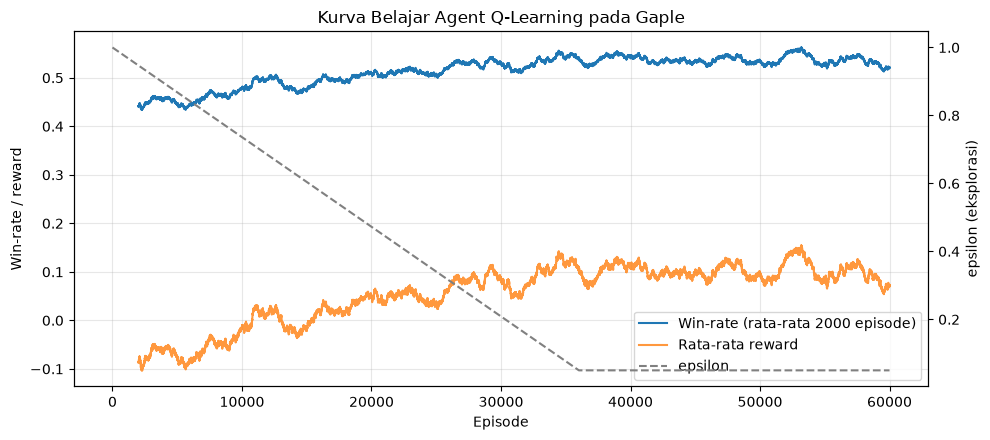

In [10]:
def moving_avg(x, w=2000):
    return np.convolve(x, np.ones(w) / w, mode='valid')

wins = (rewards == 1).astype(float)
eps_curve = [agent.epsilon(ep, N_EPISODES) for ep in range(N_EPISODES)]

fig, ax1 = plt.subplots(figsize=(10, 4.5))
ax1.plot(np.arange(len(moving_avg(wins))) + 2000, moving_avg(wins), label='Win-rate (rata-rata 2000 episode)')
ax1.plot(np.arange(len(moving_avg(rewards))) + 2000, moving_avg(rewards), label='Rata-rata reward', alpha=0.8)
ax1.set_xlabel('Episode')
ax1.set_ylabel('Win-rate / reward')
ax1.grid(alpha=0.3)
ax2 = ax1.twinx()
ax2.plot(eps_curve, color='gray', linestyle='--', label='epsilon')
ax2.set_ylabel('epsilon (eksplorasi)')
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc='lower right')
plt.title('Kurva Belajar Agent Q-Learning pada Gaple')
plt.tight_layout()
plt.show()

## 10. Evaluasi: Agent Terlatih vs Baseline

,Policy agent,Lawan,menang,seri,kalah
0,Random,vs Random,46.5%,3.0%,50.5%
1,Random,vs Greedy,40.2%,2.9%,56.9%
2,Greedy (heuristik),vs Random,57.3%,2.5%,40.2%
3,Greedy (heuristik),vs Greedy,49.0%,3.5%,47.5%
4,Q-Learning (terlatih),vs Random,58.3%,2.7%,39.0%
5,Q-Learning (terlatih),vs Greedy,51.4%,3.0%,45.5%


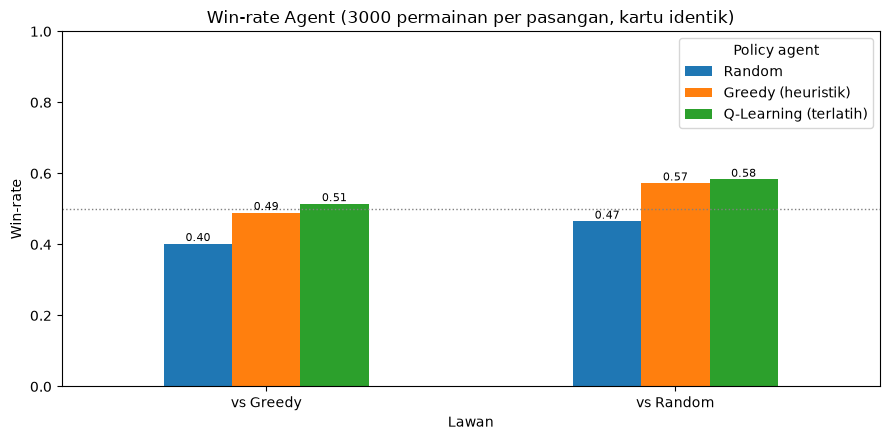

In [11]:
rows = []
for lawan, make in OPPONENTS.items():
    rows.append({'Policy agent': 'Q-Learning (terlatih)', 'Lawan': lawan, **evaluate(agent.policy(), make)})
df_eval = pd.concat([df_baseline, pd.DataFrame(rows)], ignore_index=True)
display(df_eval.style.format({'menang': '{:.1%}', 'seri': '{:.1%}', 'kalah': '{:.1%}'}))

pivot = df_eval.pivot(index='Lawan', columns='Policy agent', values='menang')
pivot = pivot[['Random', 'Greedy (heuristik)', 'Q-Learning (terlatih)']]
ax = pivot.plot(kind='bar', figsize=(9, 4.5), rot=0)
ax.set_ylabel('Win-rate')
ax.set_ylim(0, 1)
ax.axhline(0.5, color='gray', linestyle=':', linewidth=1)
for c in ax.containers:
    ax.bar_label(c, fmt='%.2f', fontsize=8)
plt.title('Win-rate Agent (3000 permainan per pasangan, kartu identik)')
plt.tight_layout()
plt.show()

## 11. Melihat Isi "Otak" Agent: Value & Policy

### 11a. Value V(s) = max Q(s, a) untuk setiap state
Heatmap ini menunjukkan seberapa "bagus" sebuah situasi menurut agent, berdasarkan jumlah kartu agent dan jumlah kartu lawan.

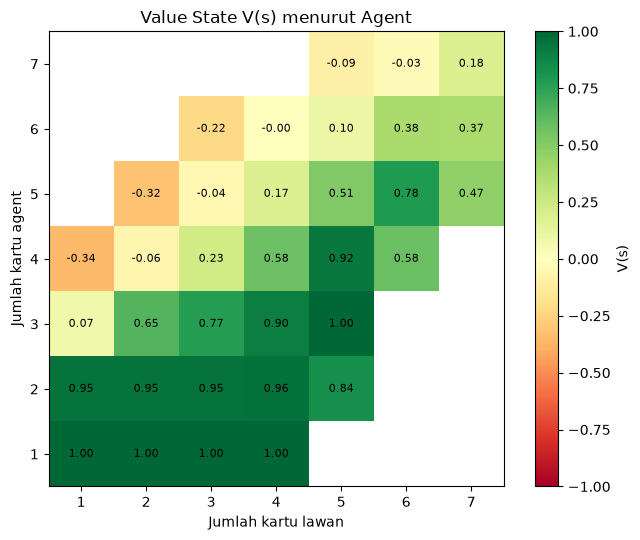

In [12]:
df_q = pd.DataFrame([dict(zip(FEATURE_NAMES, k), Q=v, N=agent.N[k]) for k, v in agent.Q.items()])
df_q = df_q[df_q.N >= 30]          # hanya entri yang cukup sering dikunjungi

V = df_q.groupby(['kartu_agent', 'kartu_lawan']).Q.max().unstack()
fig, ax = plt.subplots(figsize=(7, 5.5))
im = ax.imshow(V.values, cmap='RdYlGn', vmin=-1, vmax=1, origin='lower')
ax.set_xticks(range(len(V.columns)), V.columns)
ax.set_yticks(range(len(V.index)), V.index)
ax.set_xlabel('Jumlah kartu lawan')
ax.set_ylabel('Jumlah kartu agent')
for i in range(V.shape[0]):
    for j in range(V.shape[1]):
        if not np.isnan(V.values[i, j]):
            ax.text(j, i, f'{V.values[i, j]:.2f}', ha='center', va='center', fontsize=8)
plt.colorbar(im, label='V(s)')
plt.title('Value State V(s) menurut Agent')
plt.tight_layout()
plt.show()

### 11b. Fitur aksi apa yang disukai agent?
Rata-rata nilai Q (berbobot jumlah kunjungan) untuk setiap nilai fitur aksi. Semakin tinggi, semakin agent menyukai aksi dengan ciri tersebut.

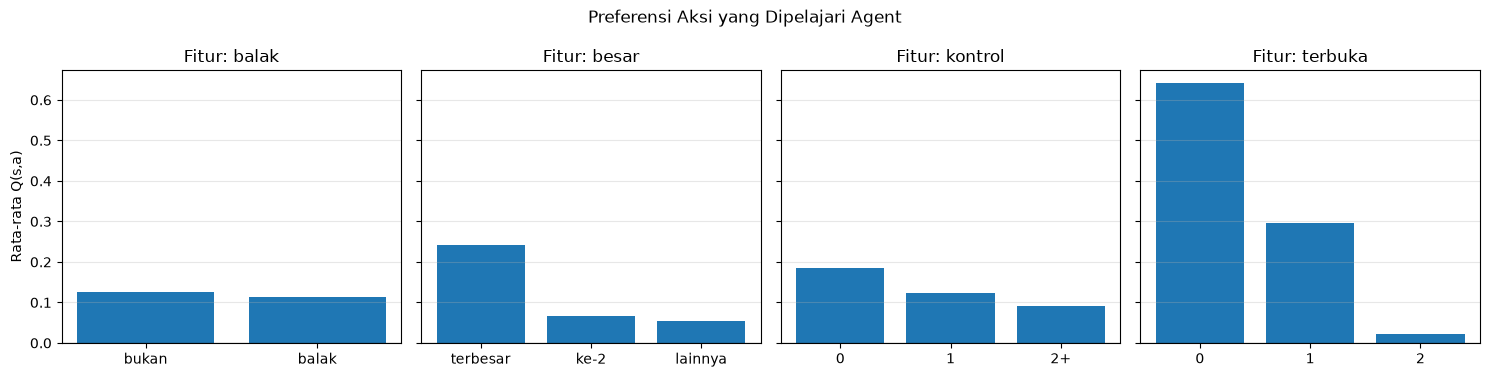

In [13]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8), sharey=True)
labels = {'balak': ['bukan', 'balak'], 'besar': ['terbesar', 'ke-2', 'lainnya'],
          'kontrol': ['0', '1', '2+'], 'terbuka': ['0', '1', '2']}
for ax, f in zip(axes, ['balak', 'besar', 'kontrol', 'terbuka']):
    g = df_q.groupby(f).apply(lambda d: np.average(d.Q, weights=d.N), include_groups=False)
    ax.bar([labels[f][i] for i in g.index], g.values, color='tab:blue')
    ax.set_title(f'Fitur: {f}')
    ax.axhline(0, color='black', linewidth=0.8)
    ax.grid(axis='y', alpha=0.3)
axes[0].set_ylabel('Rata-rata Q(s,a)')
plt.suptitle('Preferensi Aksi yang Dipelajari Agent')
plt.tight_layout()
plt.show()

### 11c. Demo permainan: bagaimana agent memilih kartu
Pada setiap giliran agent, ditampilkan pilihan aksi yang tersedia beserta nilai Q-nya. Agent memilih aksi dengan Q terbesar.

In [14]:
def demo_game(agent, opponent, seed):
    env = GapleEnv(opponent, seed=seed)
    obs = env.reset()
    print('Kartu agent awal:', ' '.join(tile_str(t) for t in obs['hand']))
    printed = 0
    while not env.done:
        for line in env.log[printed:]:
            print('   ', line)
        printed = len(env.log)
        moves = env.legal_actions()
        print(f"\n>> Giliran agent | ujung meja={obs['ends']} | kartu={' '.join(tile_str(t) for t in obs['hand'])}")
        for m in moves:
            print(f"     {tile_str(m[0])} {'kiri ' if m[1] == 'L' else 'kanan'} Q={agent.Q.get(agent.key(obs, m), 0.0):+.3f}")
        move = agent.act(obs, moves, eps=0.0)
        print(f'     => pilih {tile_str(move[0])}')
        obs, r, done = env.step(move)
    for line in env.log[printed:]:
        print('   ', line)
    print('\nReward akhir:', r)

demo_game(agent, GreedyPlayer(seed=5), seed=777)

Kartu agent awal: [0|2] [0|3] [0|4] [0|6] [2|4] [4|4] [6|6]
    Giliran pertama: Agent

>> Giliran agent | ujung meja=None | kartu=[0|2] [0|3] [0|4] [0|6] [2|4] [4|4] [6|6]
     [0|2] kiri  Q=+0.142
     [0|3] kiri  Q=+0.142
     [0|4] kiri  Q=+0.142
     [0|6] kiri  Q=+0.142
     [2|4] kiri  Q=+0.142
     [4|4] kiri  Q=+0.165
     [6|6] kiri  Q=+0.130
     => pilih [4|4]
    Agent  main [4|4] di kiri  -> ujung meja (4, 4)
    Lawan  main [4|6] di kiri  -> ujung meja (6, 4)

>> Giliran agent | ujung meja=(6, 4) | kartu=[0|2] [0|3] [0|4] [0|6] [2|4] [6|6]
     [0|4] kanan Q=+0.156
     [0|6] kiri  Q=+0.121
     [2|4] kanan Q=+0.121
     [6|6] kiri  Q=+0.123
     => pilih [0|4]
    Agent  main [0|4] di kanan -> ujung meja (6, 0)
    Lawan  main [3|6] di kiri  -> ujung meja (3, 0)

>> Giliran agent | ujung meja=(3, 0) | kartu=[0|2] [0|3] [0|6] [2|4] [6|6]
     [0|2] kanan Q=+0.149
     [0|3] kiri  Q=+0.258
     [0|3] kanan Q=+0.055
     [0|6] kanan Q=+0.161
     => pilih [0|3]
    Agent  

## 12. Eksperimen Hyperparameter

Bagaimana pengaruh **learning rate (α)** dan **discount factor (γ)** terhadap hasil belajar? (`alpha=1/N` berarti learning rate menurun sesuai jumlah kunjungan.) Setiap konfigurasi dilatih 30.000 episode lalu dievaluasi melawan GreedyPlayer.

alpha=1/N, gamma=0.95     -> win-rate vs Greedy = 0.515


alpha=0.01, gamma=0.95    -> win-rate vs Greedy = 0.466


alpha=0.1, gamma=0.95     -> win-rate vs Greedy = 0.474


alpha=0.3, gamma=0.95     -> win-rate vs Greedy = 0.453


alpha=1/N, gamma=0.5      -> win-rate vs Greedy = 0.501


alpha=1/N, gamma=1.0      -> win-rate vs Greedy = 0.519


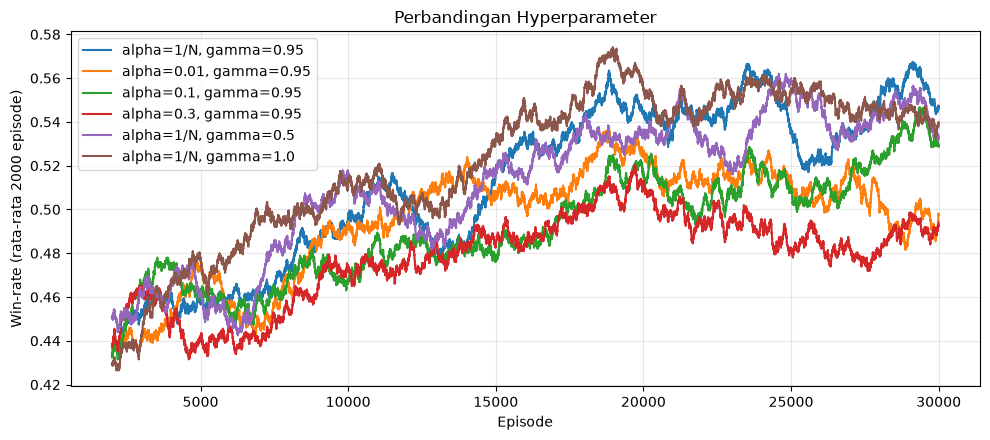

,konfigurasi,menang,seri,kalah
0,"alpha=1/N, gamma=0.95",0.515333,0.036667,0.448000
1,"alpha=0.01, gamma=0.95",0.466333,0.035667,0.498000
2,"alpha=0.1, gamma=0.95",0.474333,0.032000,0.493667
3,"alpha=0.3, gamma=0.95",0.453333,0.031667,0.515000
4,"alpha=1/N, gamma=0.5",0.500667,0.037000,0.462333
5,"alpha=1/N, gamma=1.0",0.519000,0.032000,0.449000


In [15]:
configs = [
    {'alpha': None, 'gamma': 0.95},
    {'alpha': 0.01, 'gamma': 0.95},
    {'alpha': 0.10, 'gamma': 0.95},
    {'alpha': 0.30, 'gamma': 0.95},
    {'alpha': None, 'gamma': 0.50},
    {'alpha': None, 'gamma': 1.00},
]
N_EXP = 30000
exp_rows, exp_curves = [], {}
for cfg in configs:
    a = QLearningAgent(**cfg, seed=SEED)
    rw = train(a, N_EXP, verbose=False)
    name = f"alpha={cfg['alpha'] or '1/N'}, gamma={cfg['gamma']}"
    exp_curves[name] = moving_avg((rw == 1).astype(float))
    res = evaluate(a.policy(), OPPONENTS['vs Greedy'])
    exp_rows.append({'konfigurasi': name, **res})
    print(f"{name:25s} -> win-rate vs Greedy = {res['menang']:.3f}")

df_exp = pd.DataFrame(exp_rows)

plt.figure(figsize=(10, 4.5))
for name, curve in exp_curves.items():
    plt.plot(np.arange(len(curve)) + 2000, curve, label=name)
plt.xlabel('Episode')
plt.ylabel('Win-rate (rata-rata 2000 episode)')
plt.title('Perbandingan Hyperparameter')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
df_exp

## 13. Analisis

### 13.1 Proses belajar (kurva belajar)
- Di awal training (ε ≈ 1.0) agent hampir selalu memilih kartu secara acak. Win-rate-nya sekitar **44%**, mirip baseline Random, dan rata-rata reward masih negatif (≈ −0.08).
- Seiring ε turun dan nilai Q mulai terisi, win-rate naik bertahap. Setelah ε mencapai 0.05 (sekitar episode 36.000), win-rate stabil di kisaran **52–55%** dan rata-rata reward menjadi positif (≈ +0.1).
- Kenaikan ini tidak terjadi dalam satu lonjakan, tetapi pelan dan "bergelombang". Penyebabnya, hasil gaple sangat dipengaruhi pembagian kartu (faktor keberuntungan), sehingga reward setiap episode sangat berisik walaupun policy-nya sudah membaik.
- Ini menunjukkan inti RL: agent tidak diberi label atau contoh langkah yang benar. Ia memperbaiki strateginya hanya dari interaksi dan reward menang/kalah di akhir permainan.

### 13.2 Evaluasi strategi agent
Evaluasi memakai 3000 permainan per pasangan dengan **kartu yang identik**, tanpa eksplorasi:

| Policy agent | vs Random | vs Greedy |
|---|---|---|
| Random (belum belajar) | 46.5% | 40.2% |
| Greedy (heuristik) | 57.3% | 49.0% |
| Q-Learning (terlatih) | **58.3%** | **51.4%** |

- Dibanding agent yang belum belajar (Random), agent Q-Learning naik **+11.8 poin** melawan Random dan **+11.2 poin** melawan Greedy. Peningkatan ini jelas dan konsisten di kedua lawan.
- Dibanding heuristik Greedy, agent hanya unggul tipis (+1.0 dan +2.4 poin). Dengan 3000 permainan, galat standar win-rate sekitar ±0.9%, jadi keunggulan atas Greedy masih kecil dan belum bisa disebut sangat signifikan. Meski begitu, agent berhasil mencapai (dan sedikit melampaui) strategi buatan manusia tanpa pernah diajari strategi itu.
- Melawan Greedy, win-rate agent sudah di atas 50%: agent lebih sering menang daripada kalah melawan pemain yang punya strategi.
- Angka seri kecil (≈ 3%) di semua kombinasi, karena seri hanya terjadi saat permainan buntu dan jumlah titik kedua pemain sama persis.

### 13.3 Value: heatmap V(s)
- Pola heatmap sangat masuk akal dari sudut pandang pemain gaple: **semakin sedikit kartu agent dan semakin banyak kartu lawan, semakin tinggi nilainya**.
- Saat agent tinggal 1–2 kartu, V(s) ≈ 0.84–1.00 (hampir pasti menang). Sebaliknya, saat agent masih memegang lebih banyak kartu daripada lawan (misal agent 4 vs lawan 1, atau agent 5 vs lawan 2), nilainya negatif (≈ −0.3).
- Agent tidak pernah diberi tahu bahwa "kartu sedikit itu bagus". Pengetahuan ini muncul sendiri dari reward akhir yang dirambatkan ke belakang lewat pembaruan Q-Learning ($r + \gamma \max Q(s', a')$).

### 13.4 Policy: fitur aksi yang disukai agent
- **Ujung terbuka:** fitur dengan pengaruh paling besar. Aksi yang membuat **0 ujung terbuka** (lawan dipastikan tidak bisa jalan) punya Q rata-rata ≈ 0.64, 1 ujung ≈ 0.30, dan 2 ujung hanya ≈ 0.02. Artinya agent belajar strategi **"mengunci" lawan** dengan memanfaatkan informasi saat lawan pas dan kartu yang sudah keluar. Strategi ini memang dipakai pemain gaple yang berpengalaman.
- **Besar kartu:** agent lebih suka membuang **kartu terbesar** (Q ≈ 0.24) dibanding kartu lainnya (≈ 0.05–0.07). Ini mirip strategi Greedy: jika permainan buntu, titik di tangan yang lebih kecil membuat agent menang.
- **Balak:** hampir tidak berpengaruh (0.13 vs 0.12). Dalam versi 2 pemain ini, membuang balak lebih dulu ternyata tidak terlalu penting.
- **Kontrol:** sedikit lebih tinggi untuk kontrol 0. Ini agak berlawanan dengan intuisi. Kemungkinan penyebabnya, aksi dengan kontrol 0 sering terjadi di akhir permainan saat agent tinggal sedikit kartu (yang memang nilainya tinggi), sehingga rata-ratanya ikut terangkat. Jadi rata-rata ini tidak sepenuhnya memisahkan pengaruh fitur dari pengaruh state.
- Gabungan "buang kartu besar" dan "kunci lawan" inilah yang membuat agent sedikit lebih unggul dari Greedy, yang hanya memakai aturan "buang kartu besar".

### 13.5 Eksperimen hyperparameter

| Konfigurasi | Win-rate vs Greedy |
|---|---|
| α = 1/N, γ = 0.95 | 51.5% |
| α = 0.01, γ = 0.95 | 46.6% |
| α = 0.10, γ = 0.95 | 47.4% |
| α = 0.30, γ = 0.95 | 45.3% |
| α = 1/N, γ = 0.50 | 50.1% |
| α = 1/N, γ = 1.00 | 51.9% |

- **Learning rate** adalah faktor paling berpengaruh. Learning rate **1/N** (menurun sesuai jumlah kunjungan) jauh lebih baik (≈ 51–52%) dibanding learning rate konstan (45–47%). Dengan α konstan, nilai Q terus "terombang-ambing" mengikuti hasil permainan terakhir yang sangat dipengaruhi keberuntungan. Makin besar α (0.3), makin buruk hasilnya (45.3%, bahkan di bawah Greedy). Sedangkan 1/N membuat Q menjadi rata-rata dari semua pengalaman, sehingga lebih stabil.
- **Discount factor**: γ = 0.95 dan γ = 1.0 hampir sama (51.5% vs 51.9%, masih dalam batas galat), sedangkan γ = 0.5 sedikit lebih rendah (50.1%). Reward gaple hanya datang di akhir permainan, sehingga γ yang kecil membuat informasi menang/kalah "melemah" sebelum sampai ke langkah-langkah awal. Karena satu permainan relatif pendek (± 5–7 langkah agent), γ tinggi lebih cocok.
- Model utama (60.000 episode) dan eksperimen (30.000 episode) dengan konfigurasi sama menghasilkan win-rate yang hampir sama (51.4% vs 51.5%). Artinya agent sudah konvergen sekitar 30.000 episode, dan training lebih lama tidak banyak menambah performa. Ini sesuai dengan kurva belajar yang mendatar setelah ε mencapai minimum.

### 13.6 Keterbatasan
- **Representasi state/aksi disederhanakan.** Agent hanya melihat jumlah kartu dan 4 fitur aksi, bukan seluruh isi tangan dan meja. Dua situasi berbeda bisa terlihat sama bagi agent, sehingga ada strategi yang tidak bisa dipelajari.
- **Versi 2 pemain** dengan 14 kartu tidur, sedangkan gaple asli biasanya 4 pemain dengan semua kartu dibagikan.
- **Lawan statis.** Agent hanya berlatih melawan Random dan Greedy, sehingga belum tentu kuat melawan pemain manusia atau strategi lain.
- **Faktor keberuntungan** pembagian kartu sangat besar, sehingga peningkatan win-rate yang bisa dicapai strategi apa pun terbatas dan butuh banyak permainan untuk mengukurnya.

## 14. Kesimpulan

1. Q-Learning berhasil diterapkan pada permainan gaple. Agent belajar hanya dari interaksi dengan environment dan reward menang/kalah di akhir permainan, tanpa contoh atau label strategi.
2. Setelah training, win-rate agent naik dari **46.5% → 58.3%** melawan pemain acak dan dari **40.2% → 51.4%** melawan pemain greedy, dibanding agent yang belum belajar. Agent juga sedikit melampaui strategi heuristik Greedy buatan manusia (57.3% dan 49.0%).
3. Dari tabel Q, terlihat bahwa agent menemukan sendiri strategi yang masuk akal: **mengunci ujung meja agar lawan pas** dan **membuang kartu bertitik besar terlebih dahulu**. Value V(s) juga menunjukkan pola logis: semakin sedikit kartu agent dibanding lawan, semakin besar peluang menang.
4. Pemilihan hyperparameter sangat berpengaruh. Learning rate menurun (1/N) jauh lebih stabil daripada learning rate konstan untuk permainan yang penuh unsur keberuntungan, dan discount factor tinggi (γ ≈ 0.95–1.0) cocok karena reward hanya diberikan di akhir permainan.
5. Peningkatan atas heuristik Greedy masih kecil. Untuk pengembangan selanjutnya, agent bisa dibuat lebih kuat dengan representasi state yang lebih lengkap (misalnya Deep Q-Network), latihan self-play melawan dirinya sendiri, dan versi 4 pemain seperti gaple aslinya.

## Referensi

- Sutton, R. S., & Barto, A. G. (2018). *Reinforcement Learning: An Introduction* (2nd ed.). MIT Press. Bab 6.5 (Q-Learning) dan Bab 9 (aproksimasi/agregasi state).
- Aturan permainan gaple/domino umum, disederhanakan untuk 2 pemain.